In [85]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

# setting pandas display options
pd.set_option(
    "display.float_format",
    lambda x: np.format_float_positional(
        x, precision=5, unique=False, fractional=False, trim="-"
    ),
)
pd.set_option("display.max_columns", None)


# versions
print(sys.executable)
print('pandas', pd.__version__)

/Users/qusaislaptop/miniconda3/envs/fnol_env/bin/python
pandas 3.1.0


In [3]:
from pathlib import Path
import sys

# Locate the project root and ensure the src directory is in the sys.path
project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "src").is_dir():
    project_root = project_root.parent

src_dir = project_root / "src"
if not src_dir.is_dir():
    raise FileNotFoundError("Could not locate the src directory from the notebook's working directory.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for path in sorted(src_dir.rglob("*")):
    kind = "DIR " if path.is_dir() else "FILE"
    # print(f"{kind} {path.relative_to(project_root)}")

# import helper functions
from src.data.loaders import load_excel
from src.utils.utils import replace_abnormal_entries

# Reading The Data 

In [4]:
df = load_excel("/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/raw/Data_Scientist_Interview_FNOL_Data.xlsx")
df.head()

,claim number,date_of_loss,notifier,loss_code,loss_description,notification_period,inception_to_loss,location_of_incident,weather_conditions,vehicle_mobile,time_hour,main_driver,ph_considered_tp_at_fault,vechile_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_insd_pass_front,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pass_multi,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_region_eastang,tp_region_eastmid,tp_region_london,tp_region_north,tp_region_northw,tp_region_outerldn,tp_region_scotland,tp_region_southe,tp_region_southw,tp_region_wales,tp_region_westmid,tp_region_yorkshire,incurred,capped incurred
0,1,2003-04-15,PH,LD003,Head on collision,22,13,Main Road,NORMAL,Y,10,Other,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,2,2003-04-20,CNF,LD003,Head on collision,1,9,Main Road,WET,Y,18,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,2801.3,2801.3
2,3,2003-04-24,CNF,LD003,Head on collision,5,17,Main Road,WET,Y,16,Y,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1220.9,1220.9
3,4,2003-05-13,CNF,LD003,Head on collision,1,23,Main Road,N/K,Y,14,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,3529.9,3529.9
4,5,2003-06-11,CNF,LD003,Head on collision,1,48,Other,N/K,N,9,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,3156,3156


# EDA

In [5]:
###### Features categories

#### Claim related features
# claim number 
# loss descritpion
# notifier
# loss code 
# injury details present 
# incident details present 

### date features 
# date of loss
# inception to loss 
# notification period 
# time hour 

### location data 
# location of incident 

### driver data 
# main driver 

### vehicle data 
# vehicle regestiration present 
# vehicle mobile 

### weather data 
# weather conditions 

### TP data 
# rest of features  

In [6]:
print(df.shape)

(7691, 46)


In [7]:
# noticed some abnormal entries in the data like N/k, n/k, #
# will replace them with np.nan
print(df['ph_considered_tp_at_fault'].value_counts(), '\n')
print(df['location_of_incident'].value_counts())

# apply the function to replace abnormal entries
df = replace_abnormal_entries(df)


ph_considered_tp_at_fault
N      4855
n/k    2654
Y       181
#         1
Name: count, dtype: int64 

location_of_incident
Minor Road        4249
Main Road         2702
Car Park           225
n/k                213
Other              117
Home Address       104
Not Applicable      56
Motorway            25
Name: count, dtype: int64


In [8]:
# checking null counts in each column after replacing abnormal entries
print(df.isnull().sum().sort_values(ascending=False)/df.shape[0] * 100)

ph_considered_tp_at_fault      34.521
weather_conditions             10.337
vehicle_mobile                  5.747
location_of_incident           2.7695
tp_region_northw                    0
tp_injury_whiplash                  0
tp_injury_traumatic                 0
tp_injury_fatality                  0
tp_injury_unclear                   0
tp_injury_nk                        0
tp_region_eastang                   0
tp_region_eastmid                   0
tp_region_london                    0
tp_region_north                     0
claim number                        0
tp_region_outerldn                  0
tp_type_other                       0
tp_region_scotland                  0
tp_region_southe                    0
tp_region_southw                    0
tp_region_wales                     0
tp_region_westmid                   0
tp_region_yorkshire                 0
incurred                            0
tp_type_nk                          0
tp_type_pass_multi                  0
tp_type_pede

In [9]:
df.describe(include='all').transpose()

#### notes 
# notfication period has negative values 
# tp_type_insd_pass_front is all zeros 
# tp_type_pass_multi is all zeros
# loss code and loss description have only one value
# try creating cyclical/new time based features from existing time based features 

### columns not sure what they mean 
# tp_type_insd_pass_back
# tp_type_insd_pass_back
# tp_type_driver
# tp_type_pass_back
# tp_type_pass_front


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
claim number,7691,NaN,NaN,NaN,3846,2220.3,1,1923.5,3846,5768.5,7691
date_of_loss,7691,3175,2014-05-08,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notifier,7691,5,PH,3807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_code,7691,1,LD003,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_description,7691,1,Head on collision,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notification_period,7691,NaN,NaN,NaN,7.1634,39.138,-18,0,1,2,1042
inception_to_loss,7691,NaN,NaN,NaN,166.85,104.45,0,75,161,253,365
location_of_incident,7478,7,Minor Road,4249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_conditions,6896,3,NORMAL,4564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_mobile,7249,2,Y,4046,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# dropping the following columns as they have only one value
df.drop(columns=['loss_code', 'loss_description', 'tp_type_insd_pass_front', 'tp_type_pass_multi'], inplace=True)
print("shape of df after dropping columns:", df.shape)

shape of df after dropping columns: (7691, 42)


In [11]:
# checking notification period column 
# 3 rows where the notification period is negative
print((df['notification_period'] < 0).sum(), '\n')

 # notificaiton period description > 0 
print(df[df['notification_period'] >= 0]['notification_period'].describe(), '\n')

# will impute the negative notification values with the median of the positive notification periods (median = 1)
median_notification_period = df[df['notification_period'] >= 0]['notification_period'].median()
print(f"Median notification period: {median_notification_period}", '\n')
df.loc[df['notification_period'] < 0, 'notification_period'] = median_notification_period

# checking if there are any negative notification periods left
print((df['notification_period'] < 0).sum(), '\n')

print(df['notification_period'].describe(), '\n')



3 

count     7688
mean     7.169
std     39.145
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 

Median notification period: 1.0 

0 

count     7691
mean    7.1666
std     39.137
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 



In [12]:
# changing dtype to datetime 
df['date_of_loss'] = pd.to_datetime(df['date_of_loss'])
# checking dtypes 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7691 entries, 0 to 7690
Data columns (total 42 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   claim number                  7691 non-null   int64         
 1   date_of_loss                  7691 non-null   datetime64[us]
 2   notifier                      7691 non-null   str           
 3   notification_period           7691 non-null   int64         
 4   inception_to_loss             7691 non-null   int64         
 5   location_of_incident          7478 non-null   str           
 6   weather_conditions            6896 non-null   str           
 7   vehicle_mobile                7249 non-null   str           
 8   time_hour                     7691 non-null   int64         
 9   main_driver                   7691 non-null   str           
 10  ph_considered_tp_at_fault     5036 non-null   str           
 11  vechile_registration_present  7691 non-nu

## The Target 

In [13]:
# 198 large loss claims above 50k 
# 1754 claims with zero incurred, claims that haven't been paid off yet 
# 48 claims with negative incurred
print(df['capped incurred'].describe(), "\n")
print(df['incurred'].describe(), "\n")

print(f"number of negative capped incurred: {(df['capped incurred'] < 0).sum()}")
print(f"number of negative incurred: {(df['incurred'] < 0).sum()}")

print(f"number of zero capped incurred: {(df['capped incurred'] == 0).sum()}")
print(f"number of zero incurred: {(df['incurred'] == 0).sum()}")

print(f"number of incurred greater than 50k: {(df['incurred'] > 50000).sum()}")

count     7691
mean    6106.9
std      11057
min     -10539
25%     24.909
50%     1237.7
75%     6258.4
max      50000
Name: capped incurred, dtype: float64 

count         7691
mean        9423.3
std          49852
min         -10539
25%         24.909
50%         1237.7
75%         6258.4
max     1.9519e+06
Name: incurred, dtype: float64 

number of negative capped incurred: 48
number of negative incurred: 48
number of zero capped incurred: 1754
number of zero incurred: 1754
number of incurred greater than 50k: 198


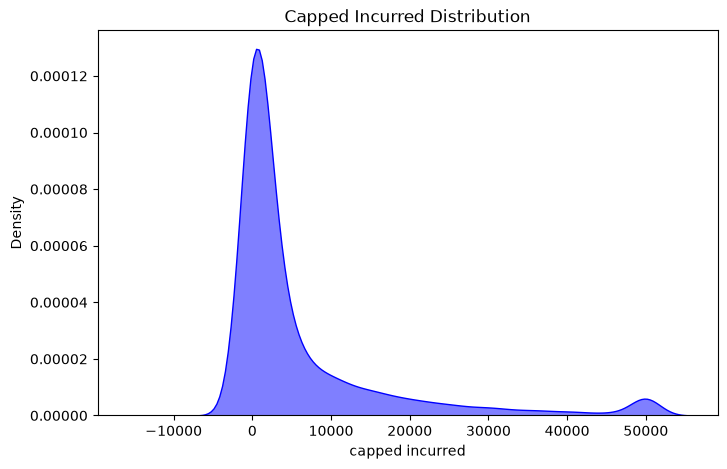

In [14]:
# plotting capped incurred distribution
plt.figure(figsize=(8,5))
sns.kdeplot(df['capped incurred'], label='Capped Incurred', shade=True, alpha=0.5,color='blue')
plt.title('Capped Incurred Distribution')
plt.show()

# Features/Target Engineering 

In [15]:
# import helper functions for feature engineering
from src.features.build_features import (build_aggregate_features, build_time_features, 
                                         add_targets, print_target_summary, 
                                         select_final_columns, set_categorical_dtypes, 
                                         check_feature_dtypes)
from src.utils.utils import save_preprocessed_data

In [16]:
# build time based/cyclical features
df = build_time_features(df)

# build third party and region aggregate features 
df = build_aggregate_features(df)

In [17]:
df.shape

(7691, 67)

In [18]:
# adding engineered targets to the df 
# y_capped, y_large, and y_incurred
df = add_targets(df)

In [19]:
# Print summary of target columns (y_capped, y_large, y_incurred)
print_target_summary(df)

Negative incurred floored to 0: 48
Share of claims with zero cost: 23.4%
Large claims (> 50,000): 198 (2.6%)
Large claims' share of total cost: 48.8%


In [20]:
# Compute Spearman correlations of numeric features with severity target y_capped
spearman_correlations = (
    df.select_dtypes(include="number")
    .drop(columns=["y_capped", "y_incurred", "incurred", "capped incurred", 'y_large'])
    .corrwith(df["y_capped"], method="spearman")
    .sort_values(ascending=False)
    .rename("spearman_correlation")
    .to_frame()
)

display(spearman_correlations.head(10))

,spearman_correlation
inj_known_share,0.52123
inj_flagged_n,0.51924
inj_severity_ord,0.50961
inj_per_tp,0.50651
tp_injury_whiplash,0.47254
tp_n_total,0.36217
tp_type_pass_front,0.2852
tp_injury_traumatic,0.23521
tp_type_pass_back,0.21648
tp_type_other,0.2073


In [21]:
# final cleaned df 
df = select_final_columns(df)
print(df.shape)
# Save the final preprocessed dataframe
save_preprocessed_data(df)

(7691, 55)


PosixPath('/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/preporcessed/preprocessed.csv')

# Model Tuning/Training

In [34]:
# import helper functions and config variables
from src.models.train_test_split import check_model_table, add_split_column, print_split_summary, get_baseline_deviance
from src.config import FEATURE_COLS, CATEGORICAL_COLS, N_TRIALS

from src.models.tuning import * 
from src.models.train import * 

In [23]:
# loading the preprocessed data 
df= pd.read_csv("/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/preporcessed/preprocessed.csv")

# convert categorical columns to category dtype for XGBoost
df = set_categorical_dtypes(df, CATEGORICAL_COLS)

#check dtypes in df 
check_feature_dtypes(df, FEATURE_COLS)

df['date_of_loss'] = pd.to_datetime(df['date_of_loss'])
df = df.reset_index(drop=True)

print(df.shape)
df.head()

Columns with unsupported dtypes: []
(7691, 55)


,claim_number,date_of_loss,notifier,location_of_incident,weather_conditions,vehicle_mobile,main_driver,ph_considered_tp_at_fault,loss_season,loss_month,loss_day_of_week,time_hour,notification_period,inception_to_loss,loss_is_weekend,loss_hour_sin,loss_hour_cos,loss_month_sin,loss_month_cos,loss_day_of_week_sin,loss_day_of_week_cos,loss_day_of_year_sin,loss_day_of_year_cos,vehicle_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_n_total,inj_flagged_n,inj_severity_ord,inj_per_tp,inj_known_share,tp_reg_east,tp_reg_london,tp_reg_midlands,tp_reg_north,tp_reg_scotland,tp_reg_south,tp_reg_wales,y_incurred,y_capped,y_large
0,1,2003-04-15,PH,Main Road,NORMAL,Y,Other,NaN,Spring,4,1,10,22,13,0,0.5,-0.86603,0.86603,-0.5,0.78183,0.62349,0.97212,-0.23449,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,2,2003-04-20,CNF,Main Road,WET,Y,Other,NaN,Spring,4,6,18,1,9,1,-1,-1.837e-16,0.86603,-0.5,-0.78183,0.62349,0.94836,-0.31719,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,2801.3,2801.3,0
2,3,2003-04-24,CNF,Main Road,WET,Y,Y,NaN,Spring,4,3,16,5,17,0,-0.86603,-0.5,0.86603,-0.5,0.43388,-0.90097,0.92429,-0.38169,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1220.9,1220.9,0
3,4,2003-05-13,CNF,Main Road,NaN,Y,Other,NaN,Spring,5,1,14,1,23,0,-0.5,-0.86603,0.5,-0.86603,0.78183,0.62349,0.75267,-0.6584,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,3529.9,3529.9,0
4,5,2003-06-11,CNF,Other,NaN,N,Other,NaN,Summer,6,2,9,1,48,0,0.70711,-0.70711,1.2246e-16,-1,0.97493,-0.22252,0.34561,-0.93838,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3156,3156,0


In [24]:
# checks on the df for Nan values, target, features and unique index 
check_model_table(df, FEATURE_COLS, CATEGORICAL_COLS)

NaNs in numeric features: 0
Ids/targets/split inside the feature list: []
Index unique: True


In [25]:
# split the data into train, validation folds, and oos sets
df = add_split_column(df)
print_split_summary(df)

             rows      first       last
split                                  
oos          2399 2014-01-01 2015-06-30
train_valid  5292 2003-04-15 2013-12-31
fold 1: train 2,875 rows, valid 576 rows
fold 2: train 3,451 rows, valid 829 rows
fold 3: train 4,280 rows, valid 1,012 rows


In [26]:
baseline_dev = get_baseline_deviance(df)
print(f"Baseline Tweedie deviance (CV): {baseline_dev:.1f}")

Baseline Tweedie deviance (CV): 218.7


## Tuning the Models 

In [27]:
help(tune_severity)

Help on function tune_severity in module src.models.tuning:

tune_severity(df: pandas.DataFrame, feature_cols: list, n_trials: int = 60) -> dict



In [28]:
# capped severity model for 100 trials 
best_severity = tune_severity(df, FEATURE_COLS, n_trials=N_TRIALS)

[I 2026-11-01 17:51:29,444] A new study created in memory with name: no-name-86c91208-1219-4d70-b13b-ad8a4c8d97e7
[I 2026-11-01 17:51:32,456] Trial 0 finished with value: 138.2862793966602 and parameters: {'tweedie_variance_power': 1.449816047538945, 'monotone': True, 'max_depth': 4, 'learning_rate': 0.014322493718230255, 'min_child_weight': 143.57772931903781, 'subsample': 0.6232334448672797, 'colsample_bytree': 0.9330880728874675, 'reg_lambda': 15.930522616241015, 'reg_alpha': 0.6796578090758157, 'gamma': 0.10292247147901223}. Best is trial 0 with value: 138.2862793966602.
[I 2026-11-01 17:51:35,697] Trial 1 finished with value: 140.7084558613335 and parameters: {'tweedie_variance_power': 1.6879639408647977, 'monotone': True, 'max_depth': 2, 'learning_rate': 0.015254729458052608, 'min_child_weight': 284.1728127339013, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.7159725093210578, 'reg_lambda': 3.8234752246751853, 'reg_alpha': 0.280163515871626, 'gamma': 0.6974693032602092}.

tweedie_deviance_p1.5: baseline 218.7406 -> best 135.0212 (n_estimators = 332, fold iterations = [471, 315, 119])


In [29]:
# large loss model for 100 trials 
best_large_loss = tune_large(df, FEATURE_COLS, n_trials=N_TRIALS)

[I 2026-11-01 17:53:56,888] A new study created in memory with name: no-name-ae4ba673-04d7-4451-8080-0b9c92bae62e
[I 2026-11-01 17:53:59,211] Trial 0 finished with value: 0.09895445186115451 and parameters: {'monotone': False, 'max_depth': 3, 'learning_rate': 0.03968793330444373, 'min_child_weight': 0.18410729205738682, 'subsample': 0.662397808134481, 'colsample_bytree': 0.5290418060840998, 'reg_lambda': 53.99484409787433, 'reg_alpha': 0.25378155082656645, 'gamma': 3.540362888980227}. Best is trial 0 with value: 0.09895445186115451.
[I 2026-11-01 17:54:00,953] Trial 1 finished with value: 0.09737151928434389 and parameters: {'monotone': False, 'max_depth': 3, 'learning_rate': 0.016305687346221478, 'min_child_weight': 0.20366442026830908, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.6521211214797689, 'reg_lambda': 11.207606211860567, 'reg_alpha': 0.05342937261279776, 'gamma': 1.4561457009902097}. Best is trial 1 with value: 0.09737151928434389.
[I 2026-11-01 17:54:02,267] Tria

logloss: baseline 0.1432 -> best 0.0963 (n_estimators = 848, fold iterations = [1349, 652, 311])


In [30]:
# saving hyperparms 
save_best_params(best_severity,"/Users/qusaislaptop/Projects/data_science/hastings_case_study/reports/tuning_params/best_severity_params.json")
save_best_params(best_large_loss,"/Users/qusaislaptop/Projects/data_science/hastings_case_study/reports/tuning_params/best_large_loss_params.json")

## Training the models 

In [31]:
severity_model, large_loss_model, mean_excess, oos_preds = train_and_score_oos(
    df, FEATURE_COLS, best_severity, best_large_loss
)

print(f"Mean excess over cap: £{mean_excess:,.0f}")

Mean excess over cap: £131,270


In [35]:
# saving the models 
save_models(severity_model, large_loss_model, "/Users/qusaislaptop/Projects/data_science/hastings_case_study/models")

# Models' Evaluation 

In [204]:
from src.models.evaluate import * 

## Train/Validation 

In [198]:
train_frame = get_train_frame(df, config.FEATURE_COLS, severity_model, large_loss_model, mean_excess)
print(train_frame.shape)
train_frame.head()

(5292, 64)


,claim_number,date_of_loss,notifier,location_of_incident,weather_conditions,vehicle_mobile,main_driver,ph_considered_tp_at_fault,loss_season,loss_month,loss_day_of_week,time_hour,notification_period,inception_to_loss,loss_is_weekend,loss_hour_sin,loss_hour_cos,loss_month_sin,loss_month_cos,loss_day_of_week_sin,loss_day_of_week_cos,loss_day_of_year_sin,loss_day_of_year_cos,vehicle_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_n_total,inj_flagged_n,inj_severity_ord,inj_per_tp,inj_known_share,tp_reg_east,tp_reg_london,tp_reg_midlands,tp_reg_north,tp_reg_scotland,tp_reg_south,tp_reg_wales,y_incurred,y_capped,y_large,split,pred_capped,prob_large,pred_total,pred_baseline,pred_baseline_total,prev_baseline,injury_flagged,loss_year
0,1,2003-04-15,PH,Main Road,NORMAL,Y,Other,NaN,Spring,4,1,10,22,13,0,0.5,-0.86603,0.86603,-0.5,0.78183,0.62349,0.97212,-0.23449,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,train_valid,985.81,0.0029298,1370.4,6393,10263,0.029478,no_injury_flagged,2003
1,2,2003-04-20,CNF,Main Road,WET,Y,Other,NaN,Spring,4,6,18,1,9,1,-1,-0.0000000000000001837,0.86603,-0.5,-0.78183,0.62349,0.94836,-0.31719,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,2801.3,2801.3,0,train_valid,2351.6,0.0031745,2768.3,6393,10263,0.029478,no_injury_flagged,2003
2,3,2003-04-24,CNF,Main Road,WET,Y,Y,NaN,Spring,4,3,16,5,17,0,-0.86603,-0.5,0.86603,-0.5,0.43388,-0.90097,0.92429,-0.38169,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1220.9,1220.9,0,train_valid,1600.7,0.0025008,1928.9,6393,10263,0.029478,no_injury_flagged,2003
3,4,2003-05-13,CNF,Main Road,NaN,Y,Other,NaN,Spring,5,1,14,1,23,0,-0.5,-0.86603,0.5,-0.86603,0.78183,0.62349,0.75267,-0.6584,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,3529.9,3529.9,0,train_valid,2526,0.0029667,2915.5,6393,10263,0.029478,no_injury_flagged,2003
4,5,2003-06-11,CNF,Other,NaN,N,Other,NaN,Summer,6,2,9,1,48,0,0.70711,-0.70711,0.00000000000000012246,-1,0.97493,-0.22252,0.34561,-0.93838,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3156,3156,0,train_valid,3367.1,0.0049831,4021.2,6393,10263,0.029478,no_injury_flagged,2003


In [ ]:
# validation folds 
valid_frames = get_validation_frames(df, FEATURE_COLS, best_severity, best_large_loss)
print({name: frame.shape for name, frame in valid_frames.items()})

# put them into a dataframe
valid_pooled = pd.concat(valid_frames.values())
print(valid_pooled.shape)
valid_pooled.head()

{'valid_2011': (576, 64), 'valid_2012': (829, 64), 'valid_2013': (1012, 64)}
(2417, 64)


,claim_number,date_of_loss,notifier,location_of_incident,weather_conditions,vehicle_mobile,main_driver,ph_considered_tp_at_fault,loss_season,loss_month,loss_day_of_week,time_hour,notification_period,inception_to_loss,loss_is_weekend,loss_hour_sin,loss_hour_cos,loss_month_sin,loss_month_cos,loss_day_of_week_sin,loss_day_of_week_cos,loss_day_of_year_sin,loss_day_of_year_cos,vehicle_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_n_total,inj_flagged_n,inj_severity_ord,inj_per_tp,inj_known_share,tp_reg_east,tp_reg_london,tp_reg_midlands,tp_reg_north,tp_reg_scotland,tp_reg_south,tp_reg_wales,y_incurred,y_capped,y_large,split,pred_capped,prob_large,pred_total,pred_baseline,pred_baseline_total,prev_baseline,injury_flagged,loss_year
2875,2876,2011-01-01,Other,Minor Road,NORMAL,NaN,Y,N,Winter,1,5,15,3,194,1,-0.70711,-0.70711,0.5,0.86603,-0.97493,-0.22252,0.017213,0.99985,1,1,0,0,1,1,1,0,0,0,0,0,3,0,0,0,0,3,3,1,1,1,3,0,0,0,0,0,0,23368,23368,0,train_valid,21469,0.08457,34450,6370,10534,0.02713,injury_flagged,2011
2876,2877,2011-01-02,PH,Minor Road,NORMAL,N,Y,N,Winter,1,6,21,1,269,1,-0.70711,0.70711,0.5,0.86603,-0.78183,0.62349,0.034422,0.99941,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,147.29,147.29,0,train_valid,3590.6,0.0065384,4594.2,6370,10534,0.02713,no_injury_flagged,2011
2877,2878,2011-01-03,Other,NaN,NaN,NaN,Other,N,Winter,1,0,0,169,5,0,0,1,0.5,0.86603,0,1,0.05162,0.99867,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,1,1,1,1,0,0,1,0,0,0,0,9013.9,9013.9,0,train_valid,4121.5,0.030425,8791.6,6370,10534,0.02713,injury_flagged,2011
2878,2879,2011-01-04,PH,Main Road,NORMAL,Y,Y,N,Winter,1,1,10,42,206,0,0.5,-0.86603,0.5,0.86603,0.78183,0.62349,0.068802,0.99763,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,train_valid,497.1,0.0050023,1264.9,6370,10534,0.02713,no_injury_flagged,2011
2879,2880,2011-01-04,PH,Main Road,NORMAL,N,Y,N,Winter,1,1,10,0,299,0,0.5,-0.86603,0.5,0.86603,0.78183,0.62349,0.068802,0.99763,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1976.8,1976.8,0,train_valid,3221.9,0.0044773,3909.1,6370,10534,0.02713,no_injury_flagged,2011


In [218]:
# train and pooled valid metrics 
frames = {"train": train_frame, "valid_pooled": valid_pooled}
severity_split_table, large_split_table = get_split_comparison_tables(frames)
display(severity_split_table.round(3)); display(large_split_table.round(3))

,train,valid_pooled
Tweedie deviance (power 1.5),89.909,135.02
Baseline deviance,205.31,218.74
Deviance improvement vs baseline,0.562,0.383
MAE (£),3631.8,5419.4
R2,0.709,0.416
Normalised Gini,0.857,0.727
Actual / expected,1.072,0.936


,train,valid_pooled
AUC,0.945,0.916
Brier skill score,0.286,0.188
Log-loss,0.076,0.096
Actual large claims,156,78
Predicted large claims,153.11,93.603
ECE,0.003,0.006


## OOS

### Severity Model 

In [166]:
# development set
dev = df[df[config.SPLIT_COL] == config.SPLIT_TRAIN_VALID]
oos = build_oos_frame(df, oos_preds)

In [167]:
severity_metrics_table = get_severity_metrics(oos)
severity_metrics_table

,tweedie_deviance,baseline_tweedie_deviance,deviance_improvement,mae,baseline_mae,rmse,baseline_rmse,r2,gini,actual_over_expected,baseline_actual_over_expected
0,112.47,197.5,0.43054,3948.5,7156.2,7186.7,10053,0.48479,0.75491,1.0555,0.85884


In [ ]:
# decile table for actual vs predicted by decile
decile_table = get_decile_table(oos, config.PRED_CAPPED_COL, config.TARGET_CAPPED)
decile_table

,decile,n,actual_mean,predicted_mean,actual_over_expected
0,1,240,1339.6,944.68,1.418
1,2,240,1110.3,1241.5,0.89435
2,3,240,1138.4,1394.1,0.81662
3,4,240,1382.7,1570.3,0.88053
4,5,240,2284.1,1818,1.2564
5,6,239,2383,2319.4,1.0274
6,7,240,3195.1,3009,1.0619
7,8,240,5548.5,5430.4,1.0217
8,9,240,13502,12352,1.0931
9,10,240,23009,21929,1.0493


In [179]:
year_table = get_year_ae(oos, config.TARGET_CAPPED, config.PRED_CAPPED_COL)
year_table

,loss_year,n,actual,predicted,actual_over_expected
0,2014,1542,8451800,7893700,1.0707
1,2015,857,4720100,4585900,1.0293


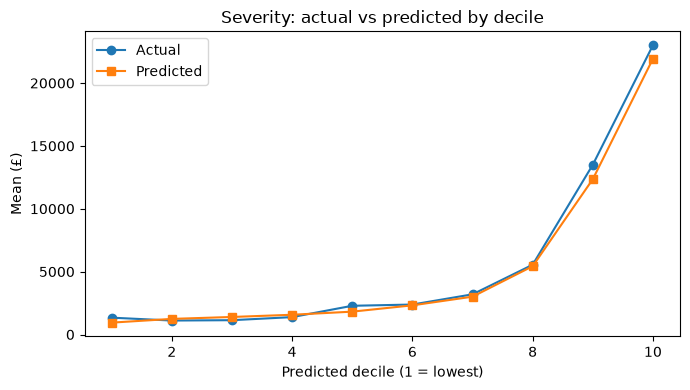

In [ ]:
# actual vs predicted by decile
plot_decile_ae(oos, title="Severity Model: actual vs predicted by decile"); 


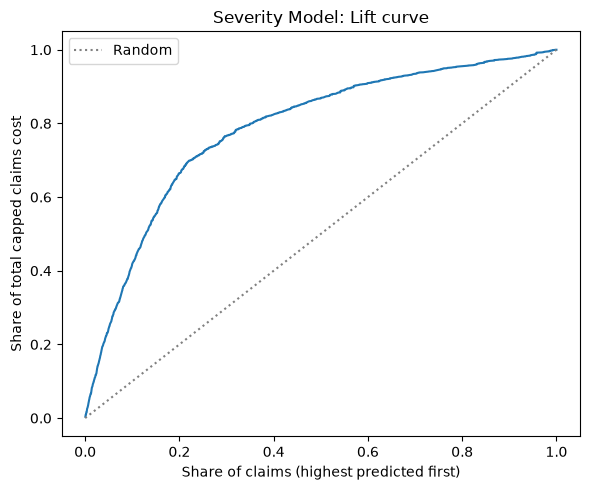

In [ ]:
# lift chart 
plot_lift(oos, title="Severity Model: Lift curve");

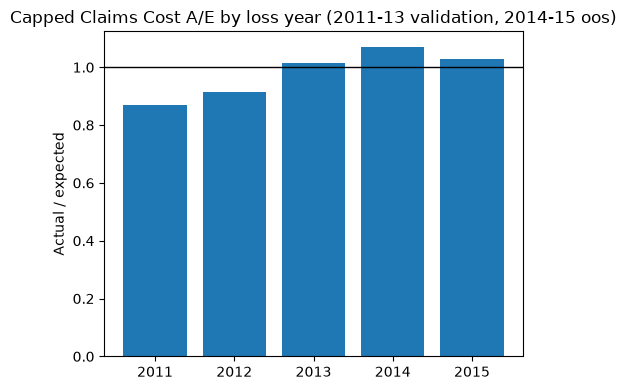

In [224]:
# actual vs predicted by loss year 
year_table_all = get_year_ae(pd.concat([valid_pooled, oos]), config.TARGET_CAPPED, config.PRED_CAPPED_COL)
plot_year_ae(year_table_all, "Capped Claims Cost A/E by loss year (2011-13 validation, 2014-15 oos)"); plt.show()

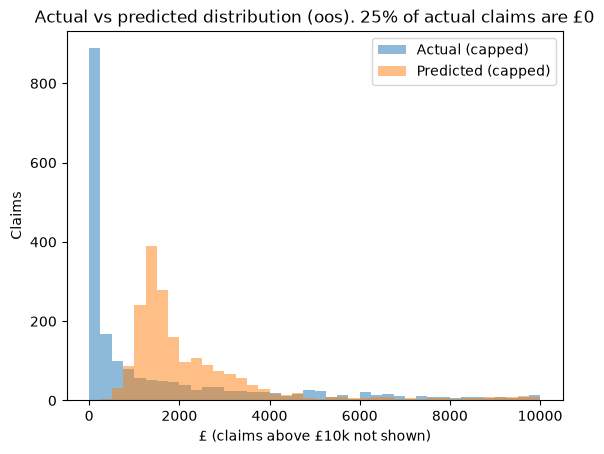

In [ ]:
# distribution of actual y_capped vs pred_capped 
sns.histplot(x=oos['y_capped'], fill=True, alpha=0.5, bins=50, kde=True)
sns.histplot(x=oos['pred_capped'], fill=True, alpha=0.5, bins=50, kde=True)
plt.legend(["Actual y_capped", "Pred Capped"])
plt.xlabel("y_capped")
plt.ylabel("Density")   
plt.xlim(xmax=10000)
plt.title("Distribution of Actual vs Predicted y_capped")

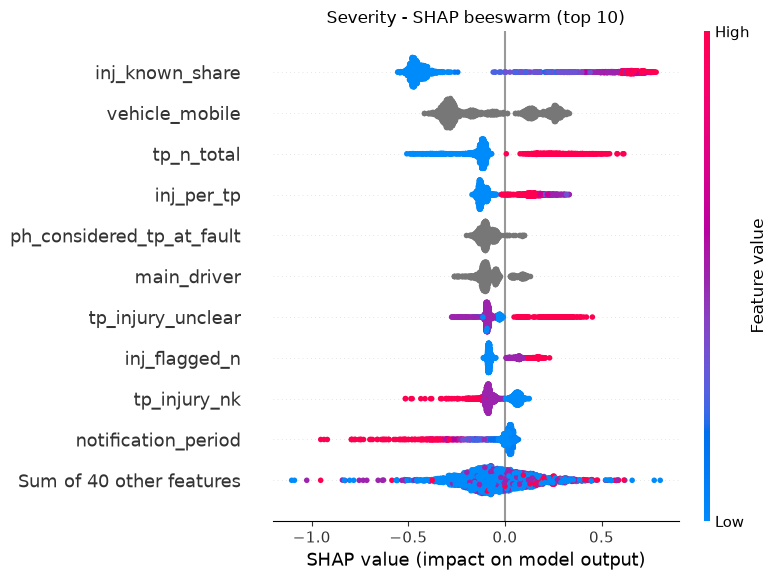

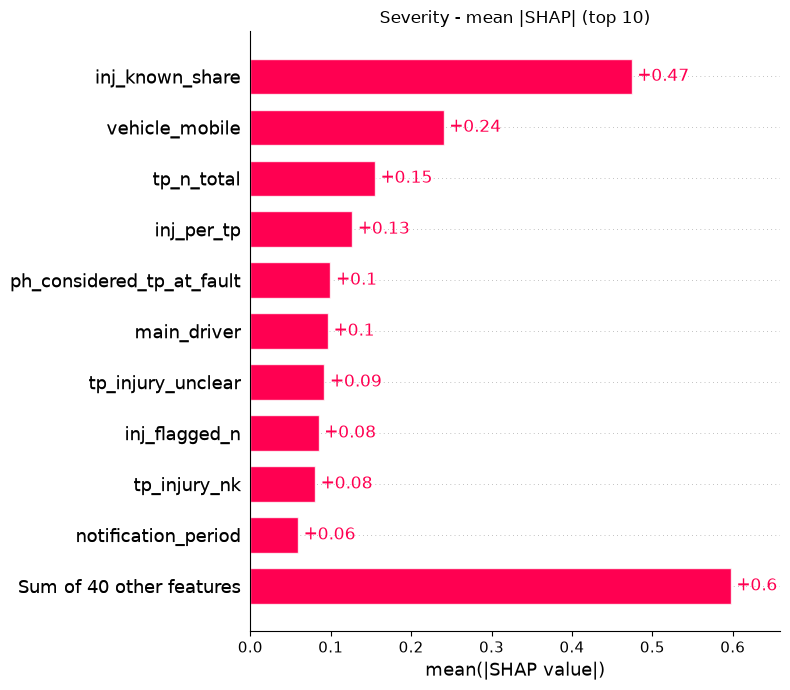

In [ ]:
# shap values for severity model
shap_severity = get_shap_values(severity_model, oos[FEATURE_COLS])
plot_shap_top_features(shap_severity, n_features=10, title="Severity");

In [221]:
# plot by factor 
plotByFactor(
    dt=oos,
    xname=config.TARGET_CAPPED,
    yname=config.TARGET_CAPPED,
    pred1=config.PRED_CAPPED_COL,
    pred2=config.PRED_BASELINE_COL,
    xacc=500,
    xmax=15000,
    xmin=None,
    logodds=False,
    chart_title="AvP capped claims cost (Severity Model)"
)

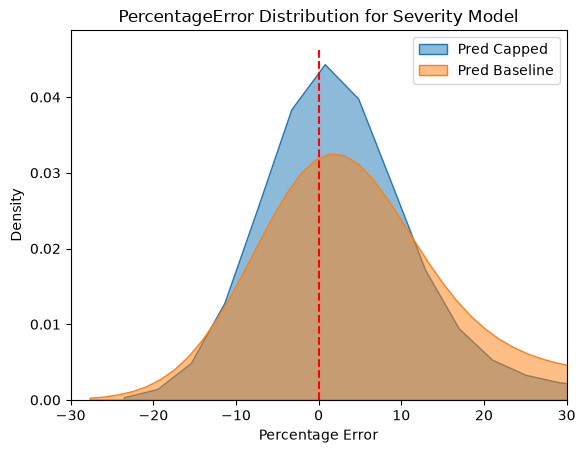

In [170]:
# error distribution for pred_capped 
sns.kdeplot(x=(oos[config.PRED_CAPPED_COL] - oos[config.TARGET_CAPPED]) / oos[config.TARGET_CAPPED], fill=True, alpha=0.5)
sns.kdeplot(x=(oos['pred_baseline'] - oos[config.TARGET_CAPPED]) / oos[config.TARGET_CAPPED], fill=True, alpha=0.5)
plt.vlines(0, 0, plt.gca().get_ylim()[1], colors='red', linestyles='dashed')
plt.legend(["Pred Capped", "Pred Baseline"])
plt.title("PercentageError Distribution for Severity Model")
plt.xlabel("Percentage Error")
plt.ylabel("Density")
plt.xlim(-30, 30)
plt.show()

### Large Loss Model 

In [ ]:
# large loss metrics df 
large_loss_metrics = get_large_metrics(oos, dev_prevalence=dev[config.TARGET_LARGE].mean())
large_loss_metrics

,n_oos,n_large_actual,n_large_predicted,calibration_in_the_large,auc,average_precision,average_precision_baseline,brier,brier_baseline,brier_skill_score,logloss,logloss_baseline,ece
0,2399,42,68.307,0.61487,0.89834,0.24443,0.017507,0.015838,0.017344,0.086857,0.066891,0.091095,0.010966


In [ ]:
# calibration table
calibration_table = get_calibration_table(oos[config.TARGET_LARGE], oos[config.PROB_LARGE_COL])
calibration_table

,bin,n,predicted_rate,observed_rate,n_large,predicted_n_large
0,1,480,0.0023337,0,0,1.1202
1,2,480,0.0030811,0.0020833,1,1.4789
2,3,479,0.0044359,0.0041754,2,2.1248
3,4,480,0.0097082,0.00625,3,4.6599
4,5,480,0.12276,0.075,36,58.923


In [ ]:
# cumulative gains table
gains_table = get_gains_table(oos) 
gains_table

,bin,n,n_large,excess_cost,share_of_claims,share_of_large,share_of_excess_cost,cum_share_of_claims,cum_share_of_large,cum_share_of_excess_cost,lift
0,1,480,36,4733400,0.20008,0.85714,0.94142,0.20008,0.85714,0.94142,4.2839
1,2,480,3,250940,0.20008,0.071429,0.049909,0.40017,0.92857,0.99133,0.35699
2,3,479,2,11446,0.19967,0.047619,0.0022765,0.59983,0.97619,0.9936,0.23849
3,4,480,1,32160,0.20008,0.02381,0.0063964,0.79992,1,1,0.119
4,5,480,0,0,0.20008,0,0,1,1,1,0


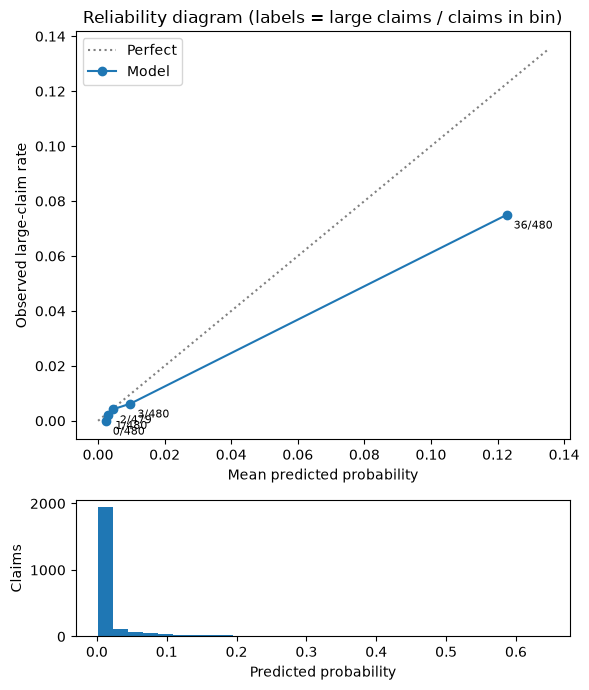

In [ ]:
# reliability plot
plot_reliability(oos);

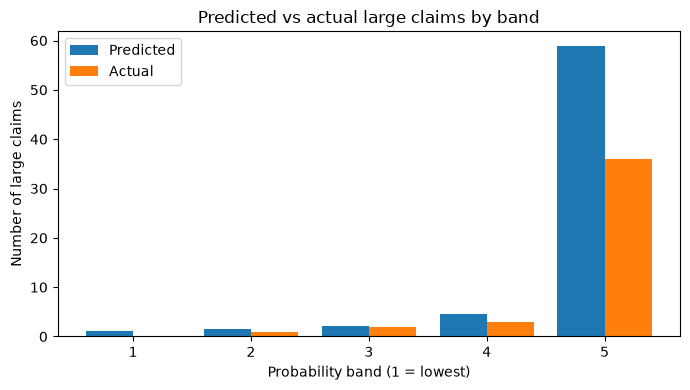

In [ ]:
# large_loss count by quintile 
plot_large_count_by_band(oos); 

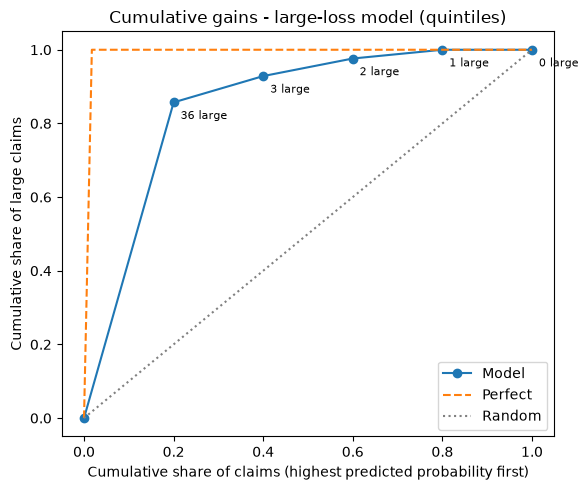

In [ ]:
# cumulative gains chart 
plot_cumulative_gains(oos);

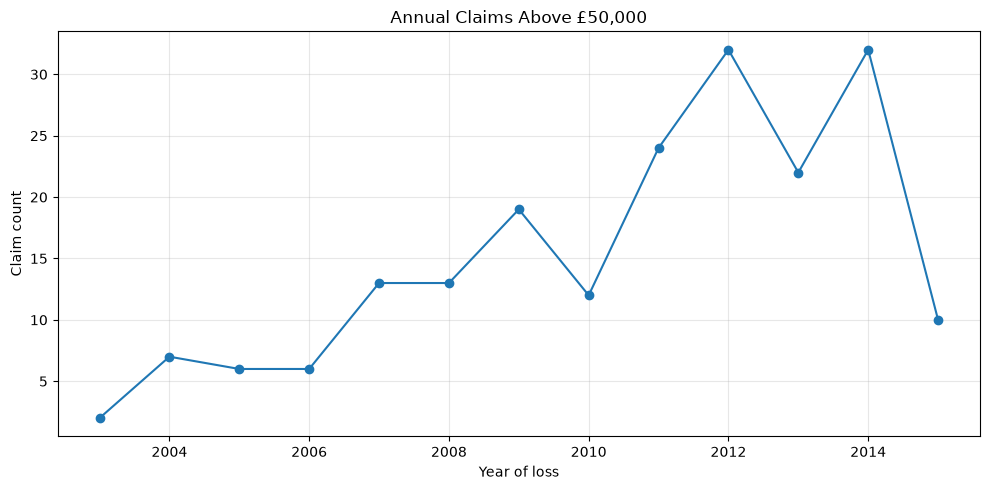

In [157]:
# time series of large loss claims by year 
annual_large_claim_counts = (
    df.assign(loss_year=pd.to_datetime(df["date_of_loss"]).dt.year)
    .loc[lambda data: data["y_incurred"] > 50_000]
    .groupby("loss_year")
    .size()
)

# Include years with no claims as zero
all_years = range(
    pd.to_datetime(df["date_of_loss"]).dt.year.min(),
    pd.to_datetime(df["date_of_loss"]).dt.year.max() + 1,
)
annual_large_claim_counts = annual_large_claim_counts.reindex(all_years, fill_value=0)

ax = annual_large_claim_counts.plot(
    kind="line", marker="o", figsize=(10, 5)
)
ax.set(
    title="Annual Claims Above £50,000",
    xlabel="Year of loss",
    ylabel="Claim count",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Combined Model 

In [173]:
total_metrics_table = get_total_metrics(oos)
total_metrics_table

,actual_total,predicted_total,baseline_predicted_total,actual_over_expected,baseline_actual_over_expected,mae,baseline_mae,rmse,baseline_rmse,r2,gini
0,18200000,21446000,24620000,0.84863,0.73923,7937,11504,29998,32442,0.13911,0.77884


In [174]:
components_table = get_total_components_table(oos)
components_table

,component,actual,predicted,actual_over_expected
0,Capped part (up to the cap),13172000,12480000,1.0555
1,Excess part (above the cap),5027900,8966600,0.56074
2,Total,18200000,21446000,0.84863


In [175]:
total_cost_table = get_total_cost_table(oos, dev)
total_cost_table

,excess_method,excess_per_large_claim,actual_total,predicted_total,actual_over_expected
0,mean,131270,18200000,21446000,0.84863
1,median,32867,18200000,14725000,1.236
2,trimmed_mean_10pct,64414,18200000,16880000,1.0782


In [178]:
total_year_table = get_year_ae(oos, config.TARGET_INCURRED, config.PRED_TOTAL_COL)
total_year_table

,loss_year,n,actual,predicted,actual_over_expected
0,2014,1542,11978000,13573000,0.88253
1,2015,857,6221500,7873500,0.79018


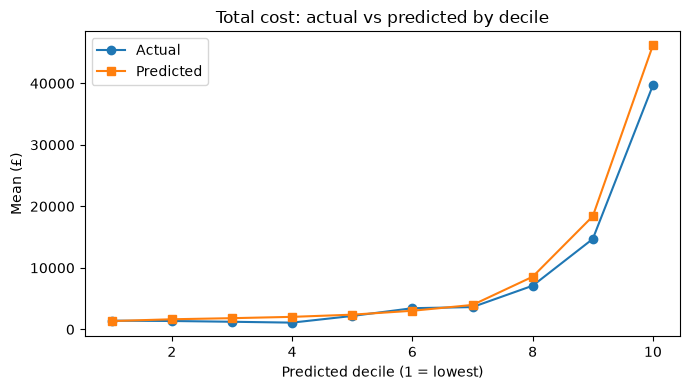

In [180]:
plot_decile_ae(oos, config.PRED_TOTAL_COL, config.TARGET_INCURRED, "Total cost: actual vs predicted by decile"); plt.show()


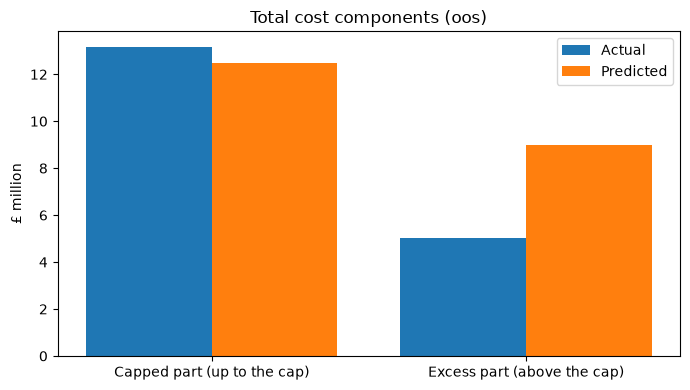

In [ ]:
plot_total_components(components_table); plt.show()

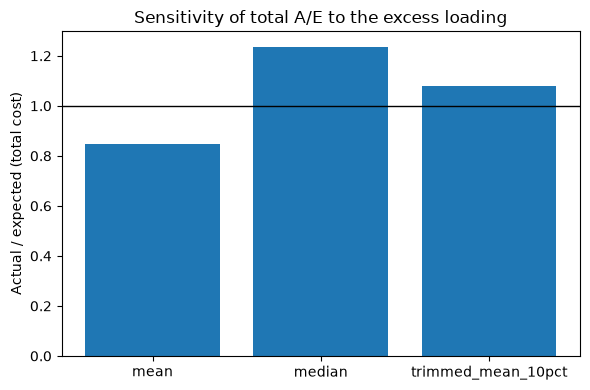

In [188]:
plot_excess_sensitivity(total_cost_table); plt.show()

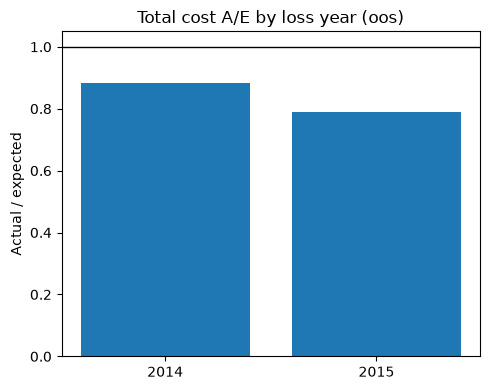

In [189]:
plot_year_ae(total_year_table, "Total cost A/E by loss year (oos)"); plt.show()
